In [ ]:
import pandas as pd

# Load and deduplicate GP-to-LSOA mapping by maximum patient volume
GP_LSOA_raw = pd.read_csv('gp-reg-pat-prac-lsoa-all.csv')
GP_LSOA = GP_LSOA_raw.sort_values(by='NUMBER_OF_PATIENTS', ascending=False).drop_duplicates(subset=['PRACTICE_CODE'], keep='first')

# Load and deduplicate LSOA-to-deprivation index mapping
LSOA_DI_raw = pd.read_csv('File_7_IoD2025_All_Ranks_Scores_Deciles_Population_Denominators.csv')
LSOA_DI = LSOA_DI_raw.drop_duplicates(subset=['LSOA_CODE'], keep='first')[['LSOA_CODE', 'IMD_DECILE']]

# Load EDP data and filter for practice code and BNF chemical substance
EDP_GP_raw= pd.read_csv('epd_snomed_202510.csv', usecols=['PRACTICE_CODE', 'BNF_CHEMICAL_SUBSTANCE'])

glp1_drugs = ['Semaglutide', 'Tirzepatide', 'Liraglutide', 'Dulaglutide']
EDP_GP_all = EDP_GP_raw[EDP_GP_raw['BNF_CHEMICAL_SUBSTANCE'].isin(glp1_drugs)]

# Merge EDP data with GP-to-LSOA and LSOA-to-deprivation index mappings
EDP_LSOA = pd.merge(EDP_GP_all, GP_LSOA, on='PRACTICE_CODE', how='inner')
EDP_DI = pd.merge(EDP_LSOA, LSOA_DI, on='LSOA_CODE', how='inner')

# Create a complete index of IMD deciles for plotting
all_deciles = pd.Index(range(1, 11), name='IMD_DECILE')


In [ ]:

#Filter EDP data for each glp-1 drug and count occurrences by IMD decile

EDP_dulaglutide = EDP_DI[EDP_DI['BNF_CHEMICAL_SUBSTANCE'] == 'Dulaglutide']
DI_count_dulaglutide = EDP_dulaglutide['IMD_DECILE'].value_counts().reindex(all_deciles, fill_value=0).sort_index()

EDP_liraglutide = EDP_DI[EDP_DI['BNF_CHEMICAL_SUBSTANCE'] == 'Liraglutide']
DI_count_liraglutide = EDP_liraglutide['IMD_DECILE'].value_counts().reindex(all_deciles, fill_value=0).sort_index()

EDP_semaglutide = EDP_DI[EDP_DI['BNF_CHEMICAL_SUBSTANCE'] == 'Semaglutide']
DI_count_semaglutide = EDP_semaglutide['IMD_DECILE'].value_counts().reindex(all_deciles, fill_value=0).sort_index()

EDP_tirzepatide = EDP_DI[EDP_DI['BNF_CHEMICAL_SUBSTANCE'] == 'Tirzepatide']
DI_count_tirzepatide = EDP_tirzepatide['IMD_DECILE'].value_counts().reindex(all_deciles, fill_value=0).sort_index()


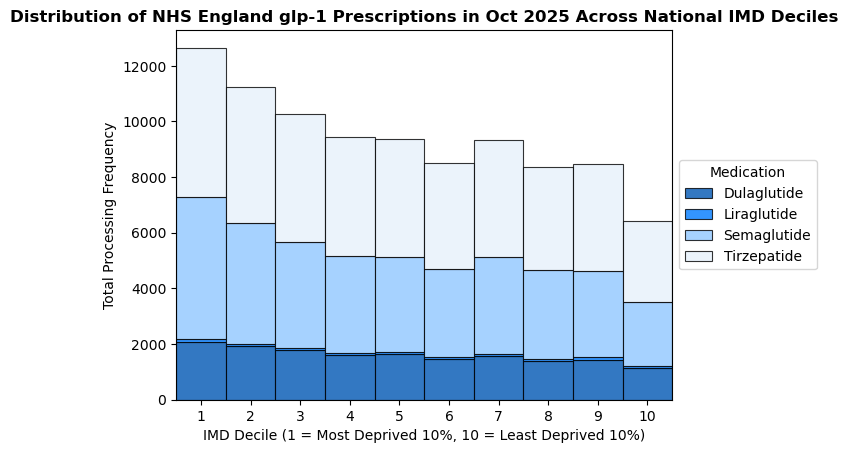

In [ ]:
import matplotlib.pyplot as plt

# Create a stacked bar chart for the distribution of GLP-1 prescriptions across IMD deciles

plt.bar(DI_count_dulaglutide.index, DI_count_dulaglutide.values, width=1, edgecolor='#000000', linewidth=0.8, color='#0056b3', alpha=0.8, label='Dulaglutide')

plt.bar(DI_count_liraglutide.index, DI_count_liraglutide.values, bottom=DI_count_dulaglutide.values, linewidth=0.8, edgecolor='#000000', width=1, color='#007bff', alpha=0.8, label='Liraglutide')

bottom_semaglutide = DI_count_dulaglutide.values + DI_count_liraglutide.values
plt.bar(DI_count_semaglutide.index, DI_count_semaglutide.values, bottom=bottom_semaglutide, width=1, linewidth=0.8, edgecolor='#000000', color='#90c7ff', alpha=0.8, label='Semaglutide')

bottom_tirzepatide = bottom_semaglutide + DI_count_semaglutide.values
plt.bar(DI_count_tirzepatide.index, DI_count_tirzepatide.values, bottom=bottom_tirzepatide, width=1, linewidth=0.8, edgecolor='#000000', color='#e6f0fa', alpha=0.8, label='Tirzepatide')

# Add labels, title, and legend to the plot
plt.title(r'Distribution of NHS England glp-1 Prescriptions in Oct 2025 Across National IMD Deciles', fontweight='bold')
plt.xlabel(r'IMD Decile (1 = Most Deprived 10%, 10 = Least Deprived 10%)')
plt.ylabel(r'Total Processing Frequency')

plt.xticks(range(1, 11))
plt.xlim(left=0.5, right=10.5)

plt.legend(title='Medication', loc='center left', bbox_to_anchor=(1, 0.5))
plt.show()

In [ ]:
# Sum all counts across the four glp-1 drugs to get total counts by IMD decile
DI_count_sorted = DI_count_dulaglutide + DI_count_liraglutide + DI_count_semaglutide + DI_count_tirzepatide
total_all = DI_count_sorted.sum()

# Calculate absolute gap between the most deprived (Decile 1) and least deprived (Decile 10) deciles
abs_gap = DI_count_sorted[1] - DI_count_sorted[10]

# Calculate disparity ratio between the most deprived (Decile 1) and least deprived (Decile 10) deciles
ratio_gap = DI_count_sorted[1] / DI_count_sorted[10]

# Calculate the percentage of prescriptions going to the most deprived half of England (Deciles 1-5)
deprived_half = DI_count_sorted.loc[1:5].sum()

# Calculate the percentage of prescriptions going to the least deprived half of England (Deciles 6-10)
affluent_half = DI_count_sorted.loc[6:10].sum()

# Calculate the percentage of prescriptions going to the most deprived half of England (Deciles 1-5)
deprived_pct = (deprived_half / total_all) * 100

# Calculate the percentage of prescriptions going to the least deprived half of England (Deciles 6-10)
drug_counts = EDP_DI['BNF_CHEMICAL_SUBSTANCE'].value_counts()
drug_pct = (drug_counts / total_all) * 100

# Print the results
print(f"Total Filtered Dataset Rows: {total_all:,}")
print(f"Absolute Gap (Decile 1 vs 10): {abs_gap:,} records")
print(f"Disparity Ratio: {ratio_gap:.2f}x higher in Decile 1")
print(f"Percentage of prescriptions going to the most deprived half of England (Deciles 1-5): {deprived_pct:.1f}%")
print("\nMarket Share Breakdowns:")
for drug, pct in drug_pct.items():
    print(f"- {drug}: {pct:.1f}% ({drug_counts[drug]:,} records)")


Total Filtered Dataset Rows: 94,063
Absolute Gap (Decile 1 vs 10): 6,219 records
Disparity Ratio: 1.97x higher in Decile 1
Percentage of prescriptions going to the most deprived half of England (Deciles 1-5): 56.3%

Market Share Breakdowns:
- Tirzepatide: 44.5% (41,860 records)
- Semaglutide: 37.6% (35,377 records)
- Dulaglutide: 17.0% (16,001 records)
- Liraglutide: 0.9% (825 records)
